## Mini Batch (refactored)

In [1]:
%load_ext autoreload
%autoreload 2

import time
import numpy as np
import matplotlib.pyplot as plt

from utils import prepare_data_set, load_image, get_label
from dnn import initialize_parameters, activate, propagate, propagate_backward, relu_backward, ForwardCache

In [2]:
datasets = prepare_data_set()

X_train = datasets["X_train"]
Y_train = datasets["Y_train"]
X_test = datasets["X_test"]
Y_test = datasets["Y_test"]

In [3]:
# keep_prob = 1 means no dropout
def forward_pass(X, parameters, keep_prob=1):
    L = len(parameters) // 2
    cache = []
    Aprev = X
    for l in range(1, L+1):
        Z, pc = propagate(parameters["W"+str(l)], Aprev, parameters["b"+str(l)])
        D = None
        if l == L:
            Aprev, ac = activate(Z, "sigmoid")
        else:
            Aprev, ac = activate(Z, "relu")
            if keep_prob < 1:
                D = (np.random.rand(Aprev.shape[0], Aprev.shape[1]) < keep_prob).astype(int)
                Aprev = Aprev * D
                Aprev = Aprev / keep_prob
        cache.append(ForwardCache(PropagateCache=pc, ActivationCache=ac, DropoutCache=D))
    return Aprev, cache

In [4]:
# keep_prob must be the same value the forward pass used
def backward_pass(AL, Y, caches, keep_prob=1):
    grads = {}
    L = len(caches)

    # sigmoid + binary cross-entropy: dZ = AL - Y
    dZ = AL - Y
    for l in reversed(range(1, L+1)):
        cache = caches[l-1]
        if l < L:
            dA = dAprev
            if cache.DropoutCache is not None:
                dA = dA * cache.DropoutCache
                dA = dA / keep_prob
            dZ = relu_backward(dA, cache.ActivationCache)
        dW, db, dAprev = propagate_backward(dZ, cache.PropagateCache.Aprev, cache.PropagateCache.W)
        grads["dW"+str(l)] = dW
        grads["db"+str(l)] = db

    return grads

In [5]:
def calculate_cost(AL, Y):
    m = AL.shape[1]
    AL = np.clip(AL, 1e-8, 1 - 1e-8)
    cost = -(1./m) * np.sum((np.dot(Y, np.log(AL).T) + np.dot(1-Y, np.log(1-AL).T)))
    return np.squeeze(cost)


# m is the size of the whole training set, not the mini-batch
def regularization_cost(parameters, regularization, lambd, m):
    L = len(parameters) // 2
    match regularization:
        case "L2":
            return (lambd / (2 * m)) * np.sum([np.sum(np.square(parameters["W"+str(l)])) for l in range(1, L+1)])
        case "L1":
            return (lambd / m) * np.sum([np.sum(np.absolute(parameters["W"+str(l)])) for l in range(1, L+1)])
        case _:
            return 0


def add_regularization_grads(grads, parameters, regularization, lambd, m):
    L = len(parameters) // 2
    for l in range(1, L+1):
        W = parameters["W"+str(l)]
        match regularization:
            case "L2":
                grads["dW"+str(l)] = grads["dW"+str(l)] + ((lambd / m) * W)
            case "L1":
                grads["dW"+str(l)] = grads["dW"+str(l)] + ((lambd / m) * np.sign(W))
    return grads

In [6]:
# v: average of the gradients (momentum), s: average of the squared gradients (rmsprop)
def initialize_zeros(parameters):
    return {"d"+key: np.zeros(value.shape) for key, value in parameters.items()}


def update_parameter(parameters, grads, learning_rate):
    for key in parameters:
        parameters[key] = parameters[key] - (learning_rate * grads["d"+key])
    return parameters


def update_parameter_with_momentum(parameters, grads, v, beta, learning_rate):
    for key in parameters:
        v["d"+key] = beta * v["d"+key] + (1 - beta) * grads["d"+key]
        parameters[key] = parameters[key] - learning_rate * v["d"+key]
    return parameters, v


def update_parameter_with_rmsprop(parameters, grads, s, beta, epsilon, learning_rate):
    for key in parameters:
        s["d"+key] = beta * s["d"+key] + (1 - beta) * np.power(grads["d"+key], 2)
        parameters[key] = parameters[key] - learning_rate * (grads["d"+key] / (np.sqrt(s["d"+key]) + epsilon))
    return parameters, s


# t is the number of updates so far, used for the bias correction
def update_parameter_with_adam(parameters, grads, s, v, beta1, beta2, epsilon, t, learning_rate):
    for key in parameters:
        v["d"+key] = beta1 * v["d"+key] + (1 - beta1) * grads["d"+key]
        s["d"+key] = beta2 * s["d"+key] + (1 - beta2) * np.power(grads["d"+key], 2)
        v_corrected = v["d"+key] / (1 - np.power(beta1, t))
        s_corrected = s["d"+key] / (1 - np.power(beta2, t))
        parameters[key] = parameters[key] - learning_rate * (v_corrected / (np.sqrt(s_corrected) + epsilon))
    return parameters, s, v

In [7]:
def random_mini_batches(X, Y, mini_batch_size=64, seed=3):
    np.random.seed(seed)
    m = X.shape[1]
    permutation = np.random.permutation(m)
    shuffled_X = X[:, permutation]
    shuffled_Y = Y[:, permutation].reshape((1, m))
    # the last batch holds the remainder when m doesn't divide evenly
    return [(shuffled_X[:, k:k+mini_batch_size], shuffled_Y[:, k:k+mini_batch_size])
            for k in range(0, m, mini_batch_size)]


def classify(X, parameters):
    output, _ = forward_pass(X, parameters)
    return (output > 0.5).astype(int)


def accuracy(X, Y, parameters):
    return 100 - np.mean(np.abs(classify(X, parameters) - Y)) * 100

In [8]:
# optimizer: "plain", "momentum", "rmsprop" or "adam"
# regularization: "none", "L1", "L2" (lambd sets the strength) or "dropout" (keep_prob sets it)
def dnn_model_mini_batch(X_train, Y_train, X_test, Y_test, layers_dims, iteration=2500,
                         learning_rate=0.0075, mini_batch_size=64, seed=3, optimizer="plain",
                         beta=0.9, beta1=0.9, beta2=0.999, epsilon=1e-8,
                         regularization="none", lambd=0.01, keep_prob=1, print_cost=False):

    if optimizer not in ("plain", "momentum", "rmsprop", "adam"):
        raise ValueError(f"unknown optimizer {optimizer!r}, use plain, momentum, rmsprop or adam")
    if regularization not in ("none", "L1", "L2", "dropout"):
        raise ValueError(f"unknown regularization {regularization!r}, use none, L1, L2 or dropout")
    if regularization == "dropout" and not (0 < keep_prob < 1):
        raise ValueError(f"dropout needs keep_prob in (0, 1), got {keep_prob}")
    if regularization != "dropout" and keep_prob != 1:
        raise ValueError(f"keep_prob={keep_prob} only works with regularization=\"dropout\"")

    parameters = initialize_parameters(layers_dims)
    v = initialize_zeros(parameters)
    s = initialize_zeros(parameters)
    t = 0
    m_total = X_train.shape[1]

    epoch_costs = []
    batch_costs = []
    for i in range(1, iteration+1):
        this_epoch_costs = []
        for X, Y in random_mini_batches(X_train, Y_train, mini_batch_size, seed+i):
            AL, cache = forward_pass(X, parameters, keep_prob)
            cost = calculate_cost(AL, Y) + regularization_cost(parameters, regularization, lambd, m_total)
            grads = backward_pass(AL, Y, cache, keep_prob)
            grads = add_regularization_grads(grads, parameters, regularization, lambd, m_total)

            match optimizer:
                case "plain":
                    parameters = update_parameter(parameters, grads, learning_rate)
                case "momentum":
                    parameters, v = update_parameter_with_momentum(parameters, grads, v, beta, learning_rate)
                case "rmsprop":
                    parameters, s = update_parameter_with_rmsprop(parameters, grads, s, beta, epsilon, learning_rate)
                case "adam":
                    t = t + 1
                    parameters, s, v = update_parameter_with_adam(parameters, grads, s, v, beta1, beta2, epsilon, t, learning_rate)

            this_epoch_costs.append(cost)
            batch_costs.append(cost)

        epoch_costs.append(np.average(this_epoch_costs))
        if (i % 100 == 0) and print_cost:
            print(f"Cost: {epoch_costs[-1]}")

    print(f"train_accuracy: {accuracy(X_train, Y_train, parameters)}%")
    print(f"test_accuracy: {accuracy(X_test, Y_test, parameters)}%")

    return parameters, batch_costs, epoch_costs

In [9]:
def plot_costs(batch_costs, epoch_costs, learning_rate, mini_batch_size):
    # put both on an epoch axis so the noise of each mini-batch lines up with its epoch
    batches_per_epoch = len(batch_costs) // len(epoch_costs)
    epochs = np.arange(1, len(epoch_costs) + 1)
    batch_steps = np.arange(1, len(batch_costs) + 1) / batches_per_epoch

    fig, (ax_epoch, ax_batch) = plt.subplots(2, 1, sharex=True, figsize=(8, 7))

    ax_epoch.plot(epochs, epoch_costs)
    ax_epoch.set_title(f"Average cost per epoch; learning rate = {learning_rate}")
    ax_epoch.set_ylabel("cost")

    ax_batch.plot(batch_steps, batch_costs, linewidth=0.5)
    ax_batch.set_title(f"Cost per mini-batch (size {mini_batch_size}, {batches_per_epoch} per epoch)")
    ax_batch.set_xlabel("epoch")
    ax_batch.set_ylabel("cost")

    plt.tight_layout()
    plt.show()


def weight_summary(parameters):
    L = len(parameters) // 2
    weights = np.concatenate([parameters["W"+str(l)].ravel() for l in range(1, L+1)])
    print("sum W^2:", np.sum(weights ** 2))
    print("sum |W|:", np.sum(np.abs(weights)))
    print(f"near-zero weights (|W| < 1e-3): {np.mean(np.abs(weights) < 1e-3) * 100:.1f}%")

Cost: 0.623878777340222


Cost: 0.5758902238894575


Cost: 0.5527538588597248


Cost: 0.5004183146541535


Cost: 0.5720651111383089


Cost: 0.5832203121113791


Cost: 0.6206021113499796


Cost: 0.6210272215644499


Cost: 0.6054499273376427
train_accuracy: 75.16552154903185%
test_accuracy: 59.268413247652%
Execution time: 7.58 minutes


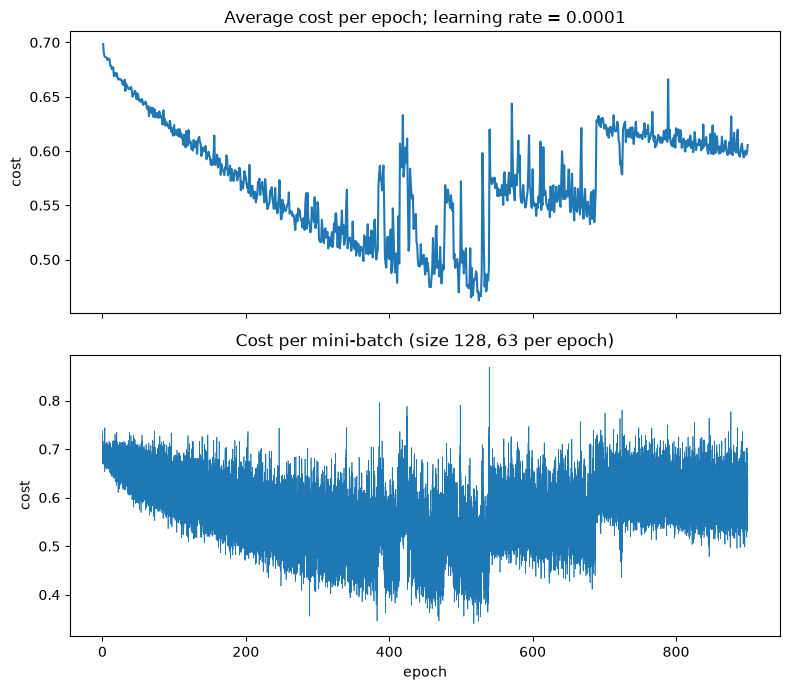

In [10]:
layers_dims = [X_train.shape[0], 30, 20, 10, 1]
learning_rate = 0.0001
mini_batch_size = 128

start_time = time.perf_counter()
parameters, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train, Y_train, X_test, Y_test, layers_dims,
        iteration=900,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        optimizer="adam",
        regularization="dropout",
        keep_prob=0.8,
        print_cost=True)
print(f"Execution time: {(time.perf_counter() - start_time) / 60:.2f} minutes")

plot_costs(batch_costs, epoch_costs, learning_rate, mini_batch_size)

In [11]:
# lambd sweep. Earlier results:
# L2: lambd 100 -> 94.6% train / 62.6% test, 300 -> 74.4% / 64.4%, 1000 collapses to 50%
# L1: lambd 1 -> 95.1% / 63.2%, 10 -> 72.0% / 62.5%
regularization = "L1"
for lambd in (7, 8, 9, 10):
    print(f"--- {regularization} lambd = {lambd}")
    parameters, batch_costs, epoch_costs = dnn_model_mini_batch(
            X_train, Y_train, X_test, Y_test, layers_dims,
            iteration=900, learning_rate=0.0001, mini_batch_size=128, optimizer="adam",
            regularization=regularization, lambd=lambd)
    weight_summary(parameters)

--- L1 lambd = 7


train_accuracy: 77.41411617738913%
test_accuracy: 61.19624320316362%
sum W^2: 20.71036747865116
sum |W|: 120.21311399227965
near-zero weights (|W| < 1e-3): 97.9%
--- L1 lambd = 8


train_accuracy: 77.48906933166771%
test_accuracy: 62.135442412259025%
sum W^2: 20.03522340149403
sum |W|: 102.87030964858218
near-zero weights (|W| < 1e-3): 98.4%
--- L1 lambd = 9


train_accuracy: 74.47845096814491%
test_accuracy: 62.432031636183886%
sum W^2: 16.231093290699985
sum |W|: 77.70937344397048
near-zero weights (|W| < 1e-3): 98.9%
--- L1 lambd = 10


train_accuracy: 71.98001249219237%
test_accuracy: 62.4814631735047%
sum W^2: 13.790859798236
sum |W|: 62.25589770959099
near-zero weights (|W| < 1e-3): 99.2%


In [12]:
for keep_prob in (0.5, 0.6, 0.7, 0.8, 0.9):
    print(f"--- dropout keep_prob = {keep_prob}")
    parameters, batch_costs, epoch_costs = dnn_model_mini_batch(
            X_train, Y_train, X_test, Y_test, layers_dims,
            iteration=900, learning_rate=0.0001, mini_batch_size=128, optimizer="adam",
            regularization="dropout", keep_prob=keep_prob)

--- dropout keep_prob = 0.5


train_accuracy: 50.031230480949404%
test_accuracy: 50.02471576866041%
--- dropout keep_prob = 0.6


train_accuracy: 57.07682698313554%
test_accuracy: 52.64458724666337%
--- dropout keep_prob = 0.7


train_accuracy: 50.031230480949404%
test_accuracy: 50.02471576866041%
--- dropout keep_prob = 0.8


train_accuracy: 75.16552154903185%
test_accuracy: 59.268413247652%
--- dropout keep_prob = 0.9


train_accuracy: 76.32729544034979%
test_accuracy: 58.37864557587741%


Deep Neural Network predict it's a dogs picture


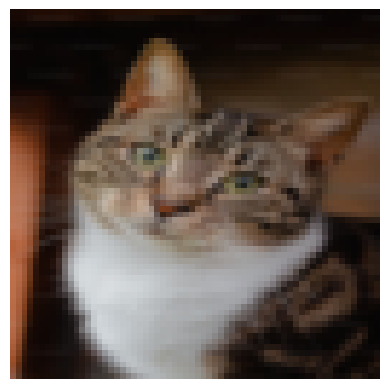

In [13]:
my_image = "cat_focus.png"
image, x_real_data = load_image(my_image)

plt.imshow(image)
plt.axis("off")

prediction = classify(x_real_data, parameters)
print(f"Deep Neural Network predict it's a {get_label(prediction)} picture")